# Greybody factors and the absorption cross-section

From the course [*Black-hole perturbation theory*](https://svykho.github.io/lab/course/) by Alejandro Svyatkovskyy Kholyavka, [Lesson 12: Compute it yourself](https://svykho.github.io/lab/course/compute.html).

Send a wave of a single, real frequency at a Schwarzschild black hole: how much of it falls in? This notebook computes the transmission through the potential barrier, the greybody factors, and adds them up into the absorption cross-section, as in the figure of [Lesson 5](https://svykho.github.io/lab/course/scattering.html). It needs NumPy, SciPy and Matplotlib and runs in under a minute.

Units: $G = c = M = 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.special import lambertw

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## The problem

With $\Psi = e^{-i\omega t}\psi(r_*)$ the wave equation becomes

$$\frac{d^2\psi}{dr_*^2} + \left[\omega^2 - V(r)\right]\psi = 0, \qquad V = \left(1 - \frac{2}{r}\right)\left[\frac{\ell(\ell+1)}{r^2} + \frac{2(1 - s^2)}{r^3}\right],$$

for a field of spin $s$: 0 for a scalar, 1 for the electromagnetic field, 2 for axial gravitational waves (the Regge–Wheeler barrier). We want the solution that is purely ingoing at the horizon,

$$\psi \to T\,e^{-i\omega r_*} \quad (r_* \to -\infty), \qquad \psi \to e^{-i\omega r_*} + R\,e^{+i\omega r_*} \quad (r_* \to +\infty).$$

The plan: start with $e^{-i\omega r_*}$ close to the horizon, integrate outwards, and far away split the result into its ingoing and outgoing parts. Dividing by the ingoing part gives $T$ and $R$.

In [2]:
def r_of_rstar(rs):
    return 2 * (1 + lambertw(np.exp(rs / 2 - 1)).real)


def potential(r, l, s):
    return (1 - 2 / r) * (l * (l + 1) / r**2 + 2 * (1 - s * s) / r**3)

## Far away

The potential falls off only as $1/r^2$, so even far away the solutions are not exactly $e^{\pm i\omega r_*}$. Write them as $e^{\pm i\omega r_*}\sum_k a_k r^{-k}$. Putting this into the equation gives a recurrence for the coefficients, with $L = \ell(\ell+1)$ and $\sigma = 2(1 - s^2)$:

$$a_{k+1} = \frac{\left[k(k+1) - L\right]a_k - \left[2(k^2 - 1) + \sigma\right]a_{k-1}}{\pm 2i\omega\,(k+1)}, \qquad a_0 = 1.$$

The series is asymptotic, not convergent: its terms first shrink and then grow. We stop at the smallest term.

In [3]:
def far_solution(w, r, l, s, sign):
    """psi = e^{sign i w r*} u(r) far away; returns u and du/dr."""
    L, sig = l * (l + 1), 2 * (1 - s * s)
    a_prev, a = 0j, 1 + 0j
    u, du, last = 1 + 0j, 0j, np.inf
    for k in range(40):
        a_next = ((k * (k + 1) - L) * a - (2 * (k * k - 1) + sig) * a_prev) / (sign * 2j * w * (k + 1))
        term = abs(a_next) / r ** (k + 1)
        if k > 1 and term > last:
            break
        last = term
        u += a_next / r ** (k + 1)
        du -= (k + 1) * a_next / r ** (k + 2)
        a_prev, a = a, a_next
    return u, du

## Integrate and split

We integrate in $r_*$ and carry $r$ along as a third unknown, with $dr/dr_* = 1 - 2/r$, so we never need to invert $r_*(r)$ during the integration. SciPy's `solve_ivp` handles complex unknowns directly; we use its eighth-order Runge–Kutta method, DOP853, which takes long steps through the oscillations.

At the outer end, match $\psi$ and $d\psi/dr_*$ to $A_{\rm in}\,\psi_- + A_{\rm out}\,\psi_+$, with $\psi_\pm$ the far solutions. Then $T = 1/A_{\rm in}$ and $R = A_{\rm out}/A_{\rm in}$.

In [4]:
def scatter(w, l, s=0):
    """Transmission and reflection probabilities |T|^2, |R|^2 at real frequency w."""
    rs0 = -40.0
    y0 = [r_of_rstar(rs0) + 0j, np.exp(-1j * w * rs0), -1j * w * np.exp(-1j * w * rs0)]
    r_end = max(100.0, 20 * (l + 1) / w)  # far enough for the far-away series

    def rhs(rs, y):
        r, psi, dpsi = y
        return [1 - 2 / r.real, dpsi, (potential(r.real, l, s) - w * w) * psi]

    def reached(rs, y):
        return y[0].real - r_end

    reached.terminal = True
    sol = solve_ivp(rhs, [rs0, 1e6], y0, method="DOP853", events=reached, rtol=1e-9, atol=1e-12)
    rs, (r, psi, dpsi) = sol.t[-1], sol.y[:, -1]
    r, f = r.real, 1 - 2 / r.real
    # the two far solutions and their derivatives in r*
    sols = []
    for sign in (-1, +1):
        u, du = far_solution(w, r, l, s, sign)
        e = np.exp(sign * 1j * w * rs)
        sols.append((e * u, e * (sign * 1j * w * u + f * du)))
    (p_in, q_in), (p_out, q_out) = sols
    det = p_in * q_out - p_out * q_in
    A_in = (psi * q_out - p_out * dpsi) / det
    A_out = (p_in * dpsi - psi * q_in) / det
    return 1 / abs(A_in) ** 2, abs(A_out) ** 2 / abs(A_in) ** 2


T2, R2 = scatter(0.3, 1)
print(f"scalar, l = 1, M omega = 0.3:  |T|^2 = {T2:.6f}   |R|^2 = {R2:.6f}")
print(f"|R|^2 + |T|^2 - 1 = {T2 + R2 - 1:.1e}")

scalar, l = 1, M omega = 0.3:  |T|^2 = 0.522644   |R|^2 = 0.477356
|R|^2 + |T|^2 - 1 = 2.2e-09


## A built-in check

Whatever the barrier, $|R|^2 + |T|^2 = 1$ (Lesson 5): energy is conserved. Nothing in the code imposes it, so it measures how accurate the integration and the far solution are.

In [5]:
for w in (0.05, 0.2, 0.5, 1.0):
    T2, R2 = scatter(w, 2, s=2)
    print(f"Regge–Wheeler, l = 2, M omega = {w:4.2f}:  |T|^2 = {T2:.3e}   |R|^2 + |T|^2 - 1 = {T2 + R2 - 1:+.1e}")

Regge–Wheeler, l = 2, M omega = 0.05:  |T|^2 = 2.687e-08   |R|^2 + |T|^2 - 1 = -1.0e-15
Regge–Wheeler, l = 2, M omega = 0.20:  |T|^2 = 8.676e-04   |R|^2 + |T|^2 - 1 = -3.2e-12
Regge–Wheeler, l = 2, M omega = 0.50:  |T|^2 = 9.845e-01   |R|^2 + |T|^2 - 1 = -5.8e-08
Regge–Wheeler, l = 2, M omega = 1.00:  |T|^2 = 1.000e+00   |R|^2 + |T|^2 - 1 = -3.3e-08


## Greybody factors

The fraction that gets through, $\Gamma_\ell = |T_\ell|^2$, for the first multipoles of a scalar field and of axial gravitational waves.

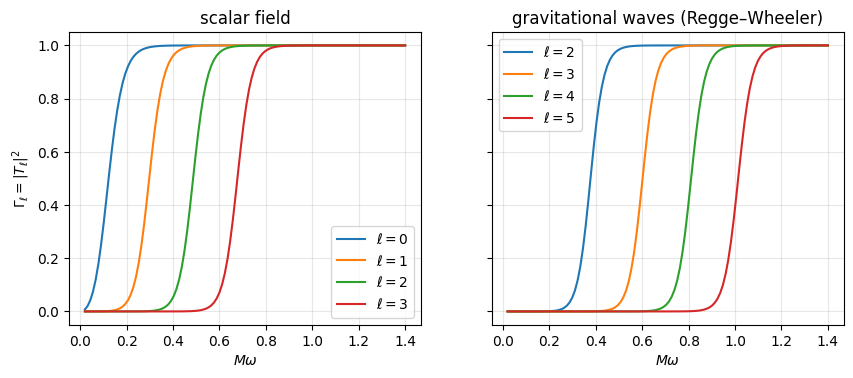

In [6]:
ws = np.linspace(0.02, 1.4, 120)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for l in (0, 1, 2, 3):
    a1.plot(ws, [scatter(w, l, 0)[0] for w in ws], label=f"$\\ell = {l}$")
for l in (2, 3, 4, 5):
    a2.plot(ws, [scatter(w, l, 2)[0] for w in ws], label=f"$\\ell = {l}$")
a1.set_title("scalar field")
a2.set_title("gravitational waves (Regge–Wheeler)")
for a in (a1, a2):
    a.set_xlabel(r"$M\omega$")
    a.legend()
a1.set_ylabel(r"$\Gamma_\ell = |T_\ell|^2$")
plt.show()

Each curve switches on where $\omega^2$ reaches the top of the barrier, and each step in $\ell$ moves it up by about $0.2/M$.

## The absorption cross-section

Add up all the multipoles of a plane wave:

$$\sigma(\omega) = \frac{\pi}{\omega^2}\sum_{\ell=0}^{\infty}(2\ell + 1)\,\Gamma_\ell(\omega).$$

At low frequency it should tend to the area of the horizon, $16\pi M^2$; at high frequency to the capture area of light, $\pi b_c^2 = 27\pi M^2$.

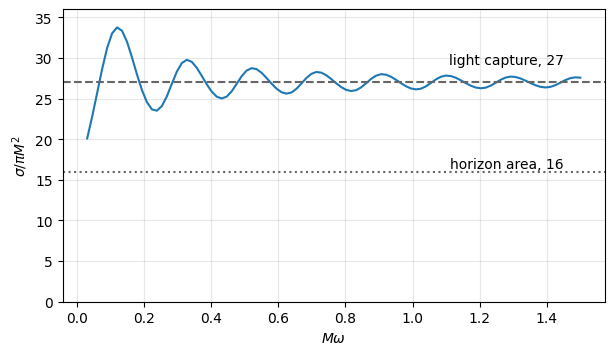

M omega = 0.03:  sigma / (pi M^2) = 20.09
M omega = 0.10:  sigma / (pi M^2) = 32.59


M omega = 0.50:  sigma / (pi M^2) = 28.23


M omega = 1.00:  sigma / (pi M^2) = 26.18


M omega = 1.50:  sigma / (pi M^2) = 27.56


In [7]:
def cross_section(w):
    total, l = 0.0, 0
    while True:
        T2 = scatter(w, l, 0)[0]
        total += (2 * l + 1) * T2
        if l > 2 and T2 < 1e-10:
            return np.pi / w**2 * total
        l += 1


ws = np.linspace(0.03, 1.5, 100)
sig = np.array([cross_section(w) for w in ws])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ws, sig / np.pi)
ax.axhline(16, ls=":", color="0.4")
ax.axhline(27, ls="--", color="0.4")
ax.text(1.45, 16.4, "horizon area, 16", ha="right")
ax.text(1.45, 29.2, "light capture, 27", ha="right")
ax.set_ylim(0, 36)
ax.set_xlabel(r"$M\omega$")
ax.set_ylabel(r"$\sigma / \pi M^2$")
plt.show()
for w in (0.03, 0.1, 0.5, 1.0, 1.5):
    print(f"M omega = {w:4.2f}:  sigma / (pi M^2) = {cross_section(w) / np.pi:.2f}")

Coming down from high frequencies, the curve wiggles around 27, with peaks spaced by about $0.19/M$, the orbital frequency of the light ring (Lesson 5). Below $M\omega \approx 0.1$ it falls towards 16, but slowly: it is still 20 at $M\omega = 0.03$ and 16.3 at $M\omega = 0.003$.

## Try this

- Compare the scalar $\ell = 0$ greybody factor at low frequency with $|T|^2 \approx 16\,\omega^2$, which follows from $\sigma \to 16\pi M^2$.
- Replace the Regge–Wheeler barrier by the Zerilli one of Lesson 4 and check that $|T|^2$ does not change.
- Compute the cross-section of the electromagnetic field ($s = 1$; its multipoles start at $\ell = 1$). What does it do at low frequency, and why is it so different from the scalar one?